# ¿Cuál es la mejor tarifa?

El objetivo de este proyecto es ayudar a Megaline a identificar qué tarifa de prepago, Surf o Ultimate, genera mayores ingresos, con el fin de orientar mejor las decisiones de marketing y presupuesto.

Para ello analizaré el comportamiento de 500 clientes durante 2018, considerando llamadas, mensajes y uso de internet. 

El plan consiste en calcular los ingresos mensuales de cada usuario según su tarifa, comparar los resultados entre planes y evaluar si existen diferencias significativas en el consumo. De esta manera, se podrá determinar cuál de las dos tarifas resulta más rentable para la empresa.

## Inicialización

In [68]:
# Cargar todas las librerías

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import scipy.stats as st

## Cargar datos

In [69]:
# Carga de archivos de datos en diferentes DataFrames

calls = pd.read_csv("datasets/megaline_calls.csv", sep=",")
internet = pd.read_csv("datasets/megaline_internet.csv", sep=",")
messages = pd.read_csv("datasets/megaline_messages.csv", sep=",")
plans = pd.read_csv("datasets/megaline_plans.csv", sep=",")
users = pd.read_csv("datasets/megaline_users.csv", sep=",")

## Preparar los datos

Previo a trabajar con los datos primero se debe revisar la información del proyecto, que está dividido en varias tablas: 

1. Revisar los archivos en Excel para reconocer la información como una primera vista.
2. Mostrar y familiarizarme con los datos con el método head() y explorar los datos con el método info()
3. Identificar los tipos de datos y si alguno debe ser cambiado para poder trabajar con ellos conforme a lo que representen
4. Identificar si hay datos duplicados explícitos e implícitos o ausentes y de ser así analizar si se deben corregir o cambiar valores para poder trabajar con ellos


Al revisar el Excel se encuentra que las columnas no están divididas como tal sino separadas por comas, hay que tomarlo en cuenta cuando se trabaje con esta información en Phyton y se importe los archivos como DataFrames.

## Tarifas

In [70]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas

print(plans.info())

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      str    
dtypes: float64(2), int64(5), str(1)
memory usage: 260.0 bytes
None


In [71]:
# Imprime una muestra de los datos para las tarifas

print(plans.head())

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  



La información se encuentra correcta y no se evidencia problema con datos. Los datos corresponden al tipo correcto:
- Enteros para minutos, mensajes, MB y precio del plan
- Flotantes para precios por mensaje y minuto
- Object para el nombre del plan
Al ser una tabla pequeña (dos tarifas) se identifica rápidamente que no hay datos duplicados ni ausentes.
Hay que tomar en cuenta que para los datos se manejan dos unidades aunque en este momento no representan problema pero si más adelante se van a realizar cálculos es importante considerarlo: el costo es por GB mientras que el consumo por mes está en MB. 


## Corregir datos

Con base en la revisión no se encontraron problemas con los datos que deban ser corregidos en la tabla de tarifas.

## Enriquecer los datos

In [72]:
# Tranformar MB a GB en la columna de mb_per_month_included

plans['gb_per_month_included'] = np.ceil(plans['mb_per_month_included']/1024).astype('int')

# Mover nueva columna junto a la columna mb_per_month_included

cols = plans.columns.tolist()
cols.remove('gb_per_month_included')
cols.insert(cols.index('mb_per_month_included') + 1, 'gb_per_month_included')
plans = plans[cols]

# Verificar la nueva columna y su ubicación

print(plans.info())
print(plans.head())

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   gb_per_month_included  2 non-null      int64  
 3   minutes_included       2 non-null      int64  
 4   usd_monthly_pay        2 non-null      int64  
 5   usd_per_gb             2 non-null      int64  
 6   usd_per_message        2 non-null      float64
 7   usd_per_minute         2 non-null      float64
 8   plan_name              2 non-null      str    
dtypes: float64(2), int64(6), str(1)
memory usage: 276.0 bytes
None
   messages_included  mb_per_month_included  gb_per_month_included  \
0                 50                  15360                     15   
1               1000                  30720                     30   

   minutes_included  usd_monthly_pay  usd_per_gb  usd_per_me

La tabla ya que cuenta con los datos necesarios de costos base por plan, costos por excedentes y nombres adecuados para las columnas. 

Es importante que los datos y el costo por datos tenga las mismas unidades y debido a que en la descripción de las tarifas se hace mención a que se redondea por GB entonces se tranforma los MB a GB para tener la misma unidad y realizar cálculos posteriores. Se mantiene las dos celdas para conservar informacion original pero ambas tienen el nombre correspondiente para evitar confusiones

## Usuarios/as

In [73]:
# Imprime la información general/resumida sobre el DataFrame de usuarios

print(users.head())

   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36   Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                          Tulsa, OK MSA   
4     1004    Leonila   Thompson   40        Seattle-Tacoma-Bellevue, WA MSA   

     reg_date      plan churn_date  
0  2018-12-24  ultimate        NaN  
1  2018-08-13      surf        NaN  
2  2018-10-21      surf        NaN  
3  2018-01-28      surf        NaN  
4  2018-05-23      surf        NaN  


In [74]:
# Imprime una muestra de datos para usuarios

print(users.info())

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     500 non-null    int64
 1   first_name  500 non-null    str  
 2   last_name   500 non-null    str  
 3   age         500 non-null    int64
 4   city        500 non-null    str  
 5   reg_date    500 non-null    str  
 6   plan        500 non-null    str  
 7   churn_date  34 non-null     str  
dtypes: int64(2), str(6)
memory usage: 31.4 KB
None


In [75]:
# Revisar si hay filas duplicadas

users_duplicados = users.duplicated().sum()
print('Total de filas duplicadas en el archivo users:', users_duplicados)


Total de filas duplicadas en el archivo users: 0


In [76]:
# Revisar si hay user_id duplicados (estos deben ser únicos)

user_id_duplicados = users['user_id'].duplicated().sum()
print('Total de userd_id duplicados en el archivo users:', user_id_duplicados)

Total de userd_id duplicados en el archivo users: 0



En cuanto a tipo de datos se identifica lo siguiente:
- Nombres de usuarios, ciudades y nombre de plan tienen el tipo correcto, object.
- User_id y edad tienen el tipo correcto, entero.
- Las fechas sin embargo tienen el tipo object y deberían tener el tipo fecha.

En referencia a información de datos nulos, hay datos nulos en la columna churn_date pero eso significa que los usuarios siguen activos.

No existen filas duplicadas ni user_id duplicados. 

### Corregir los datos

In [77]:

# Corregir el tipo de datos para las columnas que indican fechas

users['reg_date'] = pd.to_datetime(users['reg_date'])
users['churn_date'] = pd.to_datetime(users['churn_date'])

# Comprobar que se corrigió el tipo de datos para las columnas que indican fechas

print(users.info())


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    str           
 2   last_name   500 non-null    str           
 3   age         500 non-null    int64         
 4   city        500 non-null    str           
 5   reg_date    500 non-null    datetime64[us]
 6   plan        500 non-null    str           
 7   churn_date  34 non-null     datetime64[us]
dtypes: datetime64[us](2), int64(2), str(4)
memory usage: 31.4 KB
None


Se corrigió el tipo de dato para las columnas que representaban fechas y que se encontraban como object.

### Enriquecer los datos

In [78]:
# Se extraen los datos de mes para las columnas con fechas debido a que posteriormente se harán cálculos de pagos por usuario en el año 2018

users['reg_month'] = users['reg_date'].dt.month
users['churn_month'] = users['churn_date'].dt.month

# Comprobar que la tabla tiene todos los datos previos incluidas dos columnas por meses

print(users.info())
print(users.head())

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   user_id      500 non-null    int64         
 1   first_name   500 non-null    str           
 2   last_name    500 non-null    str           
 3   age          500 non-null    int64         
 4   city         500 non-null    str           
 5   reg_date     500 non-null    datetime64[us]
 6   plan         500 non-null    str           
 7   churn_date   34 non-null     datetime64[us]
 8   reg_month    500 non-null    int32         
 9   churn_month  34 non-null     float64       
dtypes: datetime64[us](2), float64(1), int32(1), int64(2), str(4)
memory usage: 37.2 KB
None
   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Belle

Pensando en que posteriormente se requerirá conocer el mes en que se registró o dejó de usar el servicio cada usuario para hacer cálculos de los pagos totales en el año se separó los meses en nuevas columnas.  

## Llamadas

In [79]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas

print(calls.info())

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  str    
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  str    
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 4.2 MB
None


In [80]:
# Imprime una muestra de datos para las llamadas

print(calls.head())

         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22


In [81]:
# Revisar si hay filas duplicadas

calls_duplicadas = calls.duplicated().sum()
print('Total de filas duplicadas en el archivo calls:', calls_duplicadas)

Total de filas duplicadas en el archivo calls: 0


In [82]:
# Revisar si hay id duplicados (estos deben ser únicos)

call_id_duplicadas = calls['id'].duplicated().sum()
print('Total de id duplicados en el archivo calls:', call_id_duplicadas)

Total de id duplicados en el archivo calls: 0



Revisando la información sobre el tipo de datos se identifica lo siguiente:
- Tipo object para la columna id, lo que es correcto.
- Tipo int64 para el user_id, que no representa un problema.
- Tipo object para la columna call_date, que debería tener el tipo fecha
- Tipo float64 para la duración, lo cual es correcto.

No se identifican valores ausentes.

Tampoco se encontraron filas o identificadores únicos duplicados.


### Corregir los datos

In [83]:
# Corregir el tipo de datos para las columnas que indican fechas

calls['call_date'] = pd.to_datetime(calls['call_date'])

# Comprobar que se corrigió el tipo de datos para las columnas que indican fechas

print(calls.info())

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  str           
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[us]
 3   duration   137735 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 4.2 MB
None


### Enriquecer los datos

In [84]:
# Convertir el dato de duration al entero más próximo en una nueva columna, debido a que Megaline redondea cada llamada individual y cualquier fracción de segundos se cuenta como un minuto.

calls['duration_rounded'] = np.ceil(calls['duration']).astype('int')

# Comprobar que la tabla tiene todos los datos previos incluida la nueva columna

print(calls.info())
print(calls.head())

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                137735 non-null  str           
 1   user_id           137735 non-null  int64         
 2   call_date         137735 non-null  datetime64[us]
 3   duration          137735 non-null  float64       
 4   duration_rounded  137735 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 5.3 MB
None
         id  user_id  call_date  duration  duration_rounded
0   1000_93     1000 2018-12-27      8.52                 9
1  1000_145     1000 2018-12-27     13.66                14
2  1000_247     1000 2018-12-27     14.48                15
3  1000_309     1000 2018-12-28      5.76                 6
4  1000_380     1000 2018-12-30      4.22                 5


In [85]:
# Se extraen los datos de mes para las columnas con fechas debido a que posteriormente se harán cálculos de pagos por usuario si exceden el límite de cada plan por mes

calls['call_month'] = calls['call_date'].dt.month

# Comprobar que la tabla tiene todos los datos previos incluida la columna por mes

print(calls.info())
print(calls.head())

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                137735 non-null  str           
 1   user_id           137735 non-null  int64         
 2   call_date         137735 non-null  datetime64[us]
 3   duration          137735 non-null  float64       
 4   duration_rounded  137735 non-null  int64         
 5   call_month        137735 non-null  int32         
dtypes: datetime64[us](1), float64(1), int32(1), int64(2), str(1)
memory usage: 5.8 MB
None
         id  user_id  call_date  duration  duration_rounded  call_month
0   1000_93     1000 2018-12-27      8.52                 9          12
1  1000_145     1000 2018-12-27     13.66                14          12
2  1000_247     1000 2018-12-27     14.48                15          12
3  1000_309     1000 2018-12-28      5.76                 6          12
4  1000_3

La columna call_date fue convertida a fecha.

Se añadió la columna duration_rounded para reflejar la política de redondeo de Megaline y para realizar futuros cálculos y se mantuvo la columna original de duration con la información original.

Se añadió la columna call_month para poder agrupar posteriormente por mes y realizar los cálculos correspondientes a los gastos de cada mes si se excedieron en lo que la tarifa otorga como parte de cada plan.

## Mensajes

In [86]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes

print(messages.info())

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            76051 non-null  str  
 1   user_id       76051 non-null  int64
 2   message_date  76051 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.7 MB
None


In [87]:
# Imprime una muestra de datos para los mensajes

print(messages.head())

         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26


In [88]:
# Revisar si hay filas duplicadas

messages_duplicados = messages.duplicated().sum()
print('Total de filas duplicadas en el DataFrame messages:', messages_duplicados)

Total de filas duplicadas en el DataFrame messages: 0


In [89]:
# Revisar si hay id duplicados (estos deben ser únicos)

messages_id_duplicados = messages['id'].duplicated().sum()
print('Total de id duplicados en el DataFrane messages:', messages_id_duplicados)

Total de id duplicados en el DataFrane messages: 0


Conforme el análisis de messages no se encuentran problemas con los datos.

El tipo object para id e int64 para user_id son correctos. Sin embargo, la columna de fecha es de tipo object. Para orden y limpieza se podría cambiar a date, aunque no es estrictamente necesaria para realizar cálculos como en otros casos. 

### Corregir los datos

In [90]:
# Corregir el tipo de datos para las columnas que indican fechas

messages['message_date'] = pd.to_datetime(messages['message_date'])


# Comprobar que se corrigió el tipo de datos para las columnas que indican fechas

print(messages.info())

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  str           
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 1.7 MB
None


### Enriquecer los datos

In [91]:
# Se extraen los datos de mes para las columnas con fechas debido a que posteriormente se harán cálculos de pagos por usuario si exceden el límite de cada plan por mes

messages['message_month'] = messages['message_date'].dt.month

# Comprobar que la tabla tiene todos los datos previos incluida la columna por mes

print(messages.info())
print(messages.head())

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             76051 non-null  str           
 1   user_id        76051 non-null  int64         
 2   message_date   76051 non-null  datetime64[us]
 3   message_month  76051 non-null  int32         
dtypes: datetime64[us](1), int32(1), int64(1), str(1)
memory usage: 2.0 MB
None
         id  user_id message_date  message_month
0  1000_125     1000   2018-12-27             12
1  1000_160     1000   2018-12-31             12
2  1000_223     1000   2018-12-31             12
3  1000_251     1000   2018-12-27             12
4  1000_255     1000   2018-12-26             12



No se identificaron datos ausentes o duplicados. 

Se cambió el tipo de datos para la columna message_date a datetime64

Se extrajo el mes de la fecha en una nueva columna llamada message_month


## Internet

In [92]:
# Imprime la información general/resumida sobre el DataFrame de internet

print(internet.info())

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  str    
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  str    
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 3.2 MB
None


In [93]:
# Imprime una muestra de datos para el tráfico de internet

print(internet.head())

         id  user_id session_date  mb_used
0   1000_13     1000   2018-12-29    89.86
1  1000_204     1000   2018-12-31     0.00
2  1000_379     1000   2018-12-28   660.40
3  1000_413     1000   2018-12-26   270.99
4  1000_442     1000   2018-12-27   880.22


In [94]:
# Revisar si hay filas duplicadas

internet_duplicados = internet.duplicated().sum()
print('El total de filas duplicadas en el DataFrame internet es:', internet_duplicados)

El total de filas duplicadas en el DataFrame internet es: 0


In [95]:
# Revisar si hay id duplicados (estos deben ser únicos)

internet_id_duplicados = internet['id'].duplicated().sum()
print('El total de id duplicados en el DataFrame internet es:', internet_id_duplicados)

El total de id duplicados en el DataFrame internet es: 0


Conforme el análisis de los datos se identifica que las columnas id, user_id y mb_used tienen el tipo de datos correcto.

La columna session_date tiene el tipo object, sin embargo, representa fecha, por lo que es necesario corregir este punto.

No se identifican datos ausentes ni duplicados. 

### Corregir los datos

In [96]:
# Convertir la columna session_date al tipo datetime

internet['session_date'] = pd.to_datetime(internet['session_date'])

# Comprobar que se corrigió el tipo de datos para las columnas que indican fechas

print(internet.info())

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  str           
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[us]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 3.2 MB
None


### Enriquecer los datos

In [97]:
# Extraer el mes de la colummna session_date con el objetivo de facilitar cálculos futuros

internet['session_month'] = internet['session_date'].dt.month

# Comprobar que se agregó la nueva columna del mes

print(internet.info())

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   id             104825 non-null  str           
 1   user_id        104825 non-null  int64         
 2   session_date   104825 non-null  datetime64[us]
 3   mb_used        104825 non-null  float64       
 4   session_month  104825 non-null  int32         
dtypes: datetime64[us](1), float64(1), int32(1), int64(1), str(1)
memory usage: 3.6 MB
None


Se cambió el tipo de datos para la columna session_date a datetime.

Se extrajo el mes de la columna session_date en una nueva columna session_month para facilitar cálculos futuros.

El dato de la columna mb_used fue transformado a gb_used debido a la política de Megaline que dice que el total del mes debe redondearse  

No se encontraron problemas adicionales con los datos.

## Estudiar las condiciones de las tarifas

In [98]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras

print(plans.info())
print(plans.head())

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   gb_per_month_included  2 non-null      int64  
 3   minutes_included       2 non-null      int64  
 4   usd_monthly_pay        2 non-null      int64  
 5   usd_per_gb             2 non-null      int64  
 6   usd_per_message        2 non-null      float64
 7   usd_per_minute         2 non-null      float64
 8   plan_name              2 non-null      str    
dtypes: float64(2), int64(6), str(1)
memory usage: 276.0 bytes
None
   messages_included  mb_per_month_included  gb_per_month_included  \
0                 50                  15360                     15   
1               1000                  30720                     30   

   minutes_included  usd_monthly_pay  usd_per_gb  usd_per_me

## Agregar datos por usuario


In [99]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.

calls_user_month = calls.groupby(['user_id','call_month'])['id'].count().reset_index()

# Se renombran columnas para tener una mejor identificacion de las mismas al unir los DataFrames

calls_user_month = calls_user_month.rename(columns = {'id': 'calls_per_month'})
calls_user_month = calls_user_month.rename(columns={'call_month':'month'})

print(calls_user_month.head())
print(calls_user_month.info())

   user_id  month  calls_per_month
0     1000     12               16
1     1001      8               27
2     1001      9               49
3     1001     10               65
4     1001     11               64
<class 'pandas.DataFrame'>
RangeIndex: 2258 entries, 0 to 2257
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   user_id          2258 non-null   int64
 1   month            2258 non-null   int32
 2   calls_per_month  2258 non-null   int64
dtypes: int32(1), int64(2)
memory usage: 44.2 KB
None


In [100]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.

minutes_user_month = calls.groupby(['user_id','call_month'])['duration_rounded'].sum().reset_index()

# Se renombran columnas para tener una mejor identificacion de las mismas al unir los DataFrames

minutes_user_month = minutes_user_month.rename(columns = {'duration_rounded': 'minutes_per_month'})
minutes_user_month = minutes_user_month.rename(columns={'call_month':'month'})

print(minutes_user_month.head())
print(minutes_user_month.info())

   user_id  month  minutes_per_month
0     1000     12                124
1     1001      8                182
2     1001      9                315
3     1001     10                393
4     1001     11                426
<class 'pandas.DataFrame'>
RangeIndex: 2258 entries, 0 to 2257
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   user_id            2258 non-null   int64
 1   month              2258 non-null   int32
 2   minutes_per_month  2258 non-null   int64
dtypes: int32(1), int64(2)
memory usage: 44.2 KB
None


In [101]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.

messages_user_month = messages.groupby(['user_id', 'message_month'])['id'].count().reset_index()

# Se renombran columnas para tener una mejor identificacion de las mismas al unir los DataFrames

messages_user_month = messages_user_month.rename(columns = {'id':'messages_per_month'})
messages_user_month = messages_user_month.rename(columns={'message_month':'month'})

print(messages_user_month.head())
print(messages_user_month.info())

   user_id  month  messages_per_month
0     1000     12                  11
1     1001      8                  30
2     1001      9                  44
3     1001     10                  53
4     1001     11                  36
<class 'pandas.DataFrame'>
RangeIndex: 1806 entries, 0 to 1805
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   user_id             1806 non-null   int64
 1   month               1806 non-null   int32
 2   messages_per_month  1806 non-null   int64
dtypes: int32(1), int64(2)
memory usage: 35.4 KB
None


In [102]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.

internet_user_month = internet.groupby(['user_id', 'session_month'])['mb_used'].sum().reset_index()

# Se renombran columnas para tener una mejor identificacion de las mismas al unir los DataFrames

internet_user_month = internet_user_month.rename(columns = {'mb_used':'mb_per_month'})
internet_user_month = internet_user_month.rename(columns={'session_month':'month'})

print(internet_user_month.head())
print(internet_user_month.info())

   user_id  month  mb_per_month
0     1000     12       1901.47
1     1001      8       6919.15
2     1001      9      13314.82
3     1001     10      22330.49
4     1001     11      18504.30
<class 'pandas.DataFrame'>
RangeIndex: 2277 entries, 0 to 2276
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   user_id       2277 non-null   int64  
 1   month         2277 non-null   int32  
 2   mb_per_month  2277 non-null   float64
dtypes: float64(1), int32(1), int64(1)
memory usage: 44.6 KB
None


In [103]:
# Se transforma los mb a gb y se redondea hacia arriba el tráfico del mes 

internet_user_month['gb_per_month_rounded'] = np.ceil(internet_user_month['mb_per_month']/1024).astype('int')

print(internet_user_month.head())
print(internet_user_month.info())

   user_id  month  mb_per_month  gb_per_month_rounded
0     1000     12       1901.47                     2
1     1001      8       6919.15                     7
2     1001      9      13314.82                    14
3     1001     10      22330.49                    22
4     1001     11      18504.30                    19
<class 'pandas.DataFrame'>
RangeIndex: 2277 entries, 0 to 2276
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               2277 non-null   int64  
 1   month                 2277 non-null   int32  
 2   mb_per_month          2277 non-null   float64
 3   gb_per_month_rounded  2277 non-null   int64  
dtypes: float64(1), int32(1), int64(2)
memory usage: 62.4 KB
None


In [104]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month

new_data = calls_user_month.merge(minutes_user_month, on = ['user_id', 'month'], how = 'outer').merge(messages_user_month, on = ['user_id', 'month'], how = 'outer').merge(internet_user_month, on = ['user_id', 'month'], how = 'outer')

new_data = new_data.fillna(0)

print(new_data.head())
print(new_data.info())

   user_id  month  calls_per_month  minutes_per_month  messages_per_month  \
0     1000     12             16.0              124.0                11.0   
1     1001      8             27.0              182.0                30.0   
2     1001      9             49.0              315.0                44.0   
3     1001     10             65.0              393.0                53.0   
4     1001     11             64.0              426.0                36.0   

   mb_per_month  gb_per_month_rounded  
0       1901.47                   2.0  
1       6919.15                   7.0  
2      13314.82                  14.0  
3      22330.49                  22.0  
4      18504.30                  19.0  
<class 'pandas.DataFrame'>
RangeIndex: 2293 entries, 0 to 2292
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               2293 non-null   int64  
 1   month                 2293 non-null   int32 

In [105]:
# Añade la información de la tarifa

# Extraer del DataFrame users solo las columnas user_id y plan que es lo que nos interesa
tarifa = users[['user_id', 'plan']]

# Unir los DataFrames
new_data = new_data.merge(tarifa, on = 'user_id')

# Renombrar en el DataFrame plans la columna plan_name para que coincida con la columna plan que se esta usando
new_plans = plans.rename(columns = {'plan_name':'plan'})

# Unir los DataFrames
new_data = new_data.merge(new_plans, on = 'plan')

print(new_data.head())
print(new_data.info())

   user_id  month  calls_per_month  minutes_per_month  messages_per_month  \
0     1000     12             16.0              124.0                11.0   
1     1001      8             27.0              182.0                30.0   
2     1001      9             49.0              315.0                44.0   
3     1001     10             65.0              393.0                53.0   
4     1001     11             64.0              426.0                36.0   

   mb_per_month  gb_per_month_rounded      plan  messages_included  \
0       1901.47                   2.0  ultimate               1000   
1       6919.15                   7.0      surf                 50   
2      13314.82                  14.0      surf                 50   
3      22330.49                  22.0      surf                 50   
4      18504.30                  19.0      surf                 50   

   mb_per_month_included  gb_per_month_included  minutes_included  \
0                  30720                     30

In [106]:
# Corregir el tipo de datos que en las uniones se convirtieron a float y deben ser int

columns_to_int = ['calls_per_month', 'minutes_per_month', 'messages_per_month', 'gb_per_month_rounded']
new_data[columns_to_int] = new_data[columns_to_int].astype(int)

print(new_data.head())
print(new_data.info())

   user_id  month  calls_per_month  minutes_per_month  messages_per_month  \
0     1000     12               16                124                  11   
1     1001      8               27                182                  30   
2     1001      9               49                315                  44   
3     1001     10               65                393                  53   
4     1001     11               64                426                  36   

   mb_per_month  gb_per_month_rounded      plan  messages_included  \
0       1901.47                     2  ultimate               1000   
1       6919.15                     7      surf                 50   
2      13314.82                    14      surf                 50   
3      22330.49                    22      surf                 50   
4      18504.30                    19      surf                 50   

   mb_per_month_included  gb_per_month_included  minutes_included  \
0                  30720                     30

Las columnas que se convirtieron a float por tener valores como NaN se vuelven a convertir a int porque los NaN ya se rellenaron con 0 y esto facilita las operaciones siguientes. Estas columnas son: calls_per_month, minutes_per_month, messages_per_month y mb_per_month_rounded.

In [107]:
# Calcula el ingreso mensual para cada usuario

# Calcular en nuevas columnas los minutos, mensajes y gb excedentes al plan

new_data['extra_minutes'] = (new_data['minutes_per_month'] - new_data['minutes_included']).clip(lower=0)
new_data['extra_messages'] = (new_data['messages_per_month']-new_data['messages_included']).clip(lower=0)
new_data['extra_gb'] = (new_data['gb_per_month_rounded'] - new_data['gb_per_month_included']).clip(lower=0)

# Verificar nuevas columnas

print(new_data[['user_id','month','plan','extra_minutes','extra_messages','extra_gb']].sample(20))
print(new_data.info())

      user_id  month      plan  extra_minutes  extra_messages  extra_gb
242      1056      8      surf              0               0         7
2249     1491      9      surf              0               0         0
342      1073      6      surf              0               0         0
1129     1240      9      surf            712               0        16
327      1071      6      surf              0               0         0
2073     1446     12      surf              0               0         5
2075     1447     11      surf              0              18        25
2103     1456      9  ultimate              0               0         0
2154     1467     10  ultimate              0               0         0
1815     1390     11  ultimate              0               0         0
461      1098     12      surf              0              48        14
648      1137     12      surf              0               6         0
1259     1264      5  ultimate              0               0   

In [108]:
# Calcular ingresos mensuales por usuario

new_data['revenue'] = (
    new_data['usd_monthly_pay'] +
    new_data['extra_minutes'] * new_data['usd_per_minute'] +
    new_data['extra_messages'] * new_data['usd_per_message'] +
    new_data['extra_gb'] * new_data['usd_per_gb']
    )

# Verificar el cálculo

print(new_data[['user_id','month','plan','revenue']].sample(20))
print(new_data.info())

      user_id  month      plan  revenue
1062     1223      7      surf   114.05
632      1133      7  ultimate    70.00
604      1128      6  ultimate    70.00
331      1071     10      surf    21.26
1952     1416     12      surf   220.00
8        1002     12      surf    20.00
942      1196      4  ultimate    70.00
400      1082      9      surf    23.51
1081     1228     10      surf    20.00
1985     1425     11      surf   110.00
296      1065     10      surf    46.69
938      1195     12      surf    28.82
2215     1483      6      surf    20.00
1039     1217     10      surf    80.84
867      1181     10      surf    50.00
581      1123      8      surf    61.56
1301     1277      8      surf   134.86
1258     1263     12      surf    82.10
1878     1403      6  ultimate    70.00
190      1047     12  ultimate    70.00
<class 'pandas.DataFrame'>
RangeIndex: 2293 entries, 0 to 2292
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------ 

Se juntaron los distintos DataFrames de llamadas, minutos, mensajes e internet en un único DataFrame, usando un outer join para no perder registros de usuarios/meses que aparecían en unos pero no en otros.

Se rellenaron los valores faltantes con 0 y se convirtieron las columnas de consumo a enteros, asegurando que representen correctamente cantidades discretas (llamadas, mensajes, MB).

Se organizó la información para que cada fila represente un único usuario en un mes determinado, con todas sus métricas de consumo consolidadas.

Se calcularon los minutos, mensajes y datos que superaban los límites incluidos en el plan, asegurando que los valores negativos se conviertan en 0.

Se sumó la tarifa fija del plan más los cargos por excedentes, obteniendo así la columna revenue que refleja el ingreso mensual por usuario.

## Estudio del comportamiento del usuario

### Llamadas

In [109]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.

# Cálculo del promedio por plan y por mes

minutes_plan_month = new_data.groupby(['plan', 'month'])['minutes_per_month'].mean()

print(minutes_plan_month.head())

# Organización de la información en una tabla

minutes_plan_month = minutes_plan_month.unstack('plan')

print(minutes_plan_month.head())


plan  month
surf  1        203.000000
      2        297.000000
      3        330.000000
      4        351.540000
      5        399.584416
Name: minutes_per_month, dtype: float64
plan         surf    ultimate
month                        
1      203.000000  193.500000
2      297.000000  403.142857
3      330.000000  304.250000
4      351.540000  336.857143
5      399.584416  406.241379


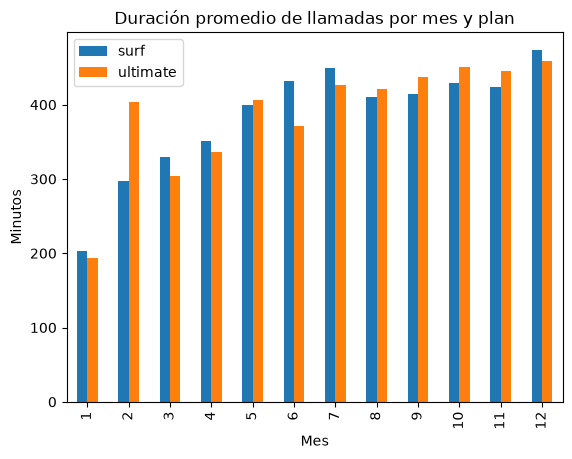

In [110]:
# Visualización con gráfico de barras

minutes_plan_month.plot(kind='bar',
           title='Duración promedio de llamadas por mes y plan',
           xlabel='Mes',
           ylabel='Minutos')

plt.legend()
plt.show()


El gráfico nos indica que no existe una variacion representativa en el promedio de duración de las llamadas por mes y por plan. Hay meses como febrero que los usuarios de ultimate hacen llamadas más largas y meses como junio que los usuarios de surf que hacen llamadas más largas. 

Lo que si coindice para los usuarios de ambos planes es que las llamadas duran más en junio y en diciembre. Y cuando menos llamadas realizan es en enero. Aunque esto también puede deberse a que el número de usuarios incremente a finales del año. 

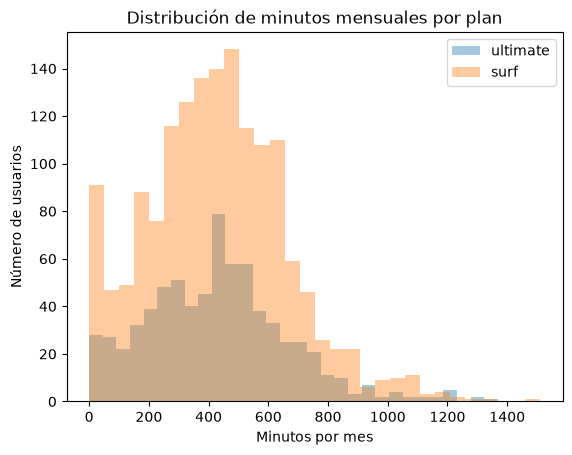

In [111]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.

for plan in new_data['plan'].unique():
    sub_data = new_data[new_data['plan'] == plan]
    plt.hist(sub_data['minutes_per_month'], bins=30, alpha=0.4, label=plan)

plt.title('Distribución de minutos mensuales por plan')
plt.xlabel('Minutos por mes')
plt.ylabel('Número de usuarios')

plt.legend()

plt.show()



Con el histograma se identifica que hay más usuarios en surf y en este plan hay mayor dispersión, esto significa que hay más variedad en el consumo de minutos. 

Tanto surf como ultimate tienen mayor numero de usuarios en llamadas de entre 400 y 500 minutos.

El gráfico de surf tiene una cola más larga hacia la derecha, lo que significa que hay usuarios que usan minutos extra al superar los 500  minutos de su plan. Lo contrario que ocurre con los usuarios de ultimate que están usando mucho menos minutos de los que están pagando. No se evidencia casos que lleguen a 3000 minutos que es lo que les otorga su plan. 

In [112]:
# Calcula la media y la varianza de la duración mensual de llamadas.

mean_ave_min_plan_month = new_data.groupby(['plan', 'month'])['minutes_per_month'].agg(['mean','var']).reset_index()

print(mean_ave_min_plan_month)

        plan  month        mean           var
0       surf      1  203.000000  15842.000000
1       surf      2  297.000000  52226.500000
2       surf      3  330.000000  35809.363636
3       surf      4  351.540000  50866.743265
4       surf      5  399.584416  59754.219754
5       surf      6  431.298969  45592.628436
6       surf      7  449.983471  61005.099725
7       surf      8  410.111111  54344.645963
8       surf      9  414.226804  46595.958656
9       surf     10  429.729958  52278.664056
10      surf     11  423.325088  51607.021602
11      surf     12  473.836478  63629.518918
12  ultimate      1  193.500000  16572.333333
13  ultimate      2  403.142857  76889.476190
14  ultimate      3  304.250000  61984.931818
15  ultimate      4  336.857143  34888.928571
16  ultimate      5  406.241379  43841.046798
17  ultimate      6  370.957447  42503.563367
18  ultimate      7  427.067797  72563.374635
19  ultimate      8  421.436620  53645.506640
20  ultimate      9  437.511628  5

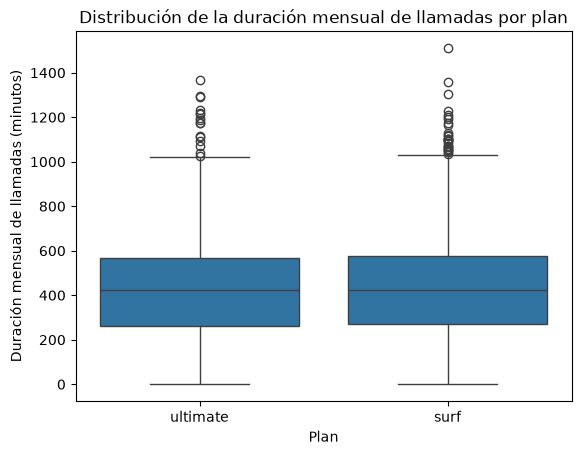

In [113]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

sns.boxplot(data=new_data, 
            x='plan', 
            y='minutes_per_month')

plt.title('Distribución de la duración mensual de llamadas por plan')
plt.xlabel('Plan')
plt.ylabel('Duración mensual de llamadas (minutos)')
plt.show()

In [114]:
# Cantidad de usuarios por plan

users_per_plan = new_data.groupby(['plan'])['user_id'].nunique().reset_index()
print(users_per_plan)

       plan  user_id
0      surf      333
1  ultimate      157


El análisis muestra que hay mayor cantidad de usuarios en el plan de surf que en ultimate, esto es importante para analizar si los datos obtenidos representan una mayor cantidad porque hay mas usuarios o porque en efecto hay más llamadas por usuario.

Al obtener la media y la varianza de los datos mensuales por plan se evidencia que no hay mayor diferencia en los usuarios de los planes. 

Al observar el histograma, se nota que que hay más usuarios de surf realizando llamadas, estas llamadas tanto para surf como para ultimate se concentran en un rango aproximado de 400 y 500 minutos mensuales.

Con el diagrama de caja se evidencia tambien comportamientos similares con un ligero incremento en surf para casos extremos, es decir, que tiene mayor dispersión, con usuarios que consumen más minutos de los que se encuentran incluidos en el plan, ya que sobrepasa los 500 minutos. 

En resumen: el plan no influye en cuánto dura cada llamada o en la cantidad de llamadas que realizan, los usuarios de ambos planes tienen comportamientos similares, aunque en cantidad se evidencia más llamadas en surf porque tiene más usuarios. Además, ultimate concentra más actividad, mientras que surf es más disperso.

### Mensajes

In [115]:
# Compara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan

stat_messages_month_plan = new_data.groupby(['plan','month'])['messages_per_month'].agg(['mean','var']).reset_index()
print(stat_messages_month_plan )

        plan  month       mean          var
0       surf      1  10.500000   220.500000
1       surf      2  12.000000   386.000000
2       surf      3  15.260870   346.565217
3       surf      4  17.400000   501.591837
4       surf      5  24.012987   847.197198
5       surf      6  25.298969   914.920103
6       surf      7  27.033058   923.915565
7       surf      8  28.777778  1029.515528
8       surf      9  30.762887  1003.829496
9       surf     10  33.839662  1275.465708
10      surf     11  32.385159  1065.344034
11      surf     12  38.600629  1458.158612
12  ultimate      1  15.500000   313.666667
13  ultimate      2  21.571429   478.285714
14  ultimate      3  20.250000   654.386364
15  ultimate      4  22.047619   544.147619
16  ultimate      5  32.103448  1297.310345
17  ultimate      6  29.340426   857.620722
18  ultimate      7  32.830508   960.488019
19  ultimate      8  38.478873  1196.367404
20  ultimate      9  37.895349  1050.918331
21  ultimate     10  39.443396  

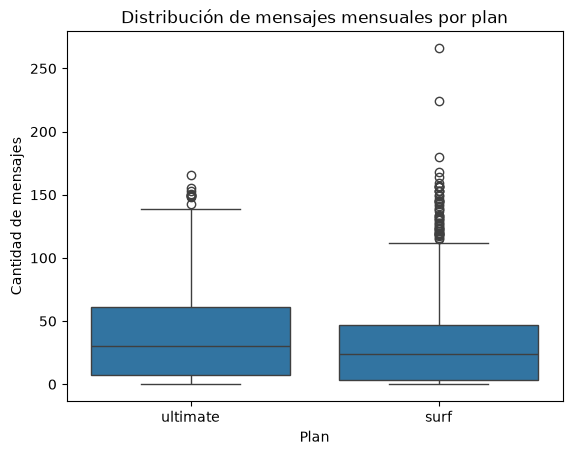

In [116]:
# Traza un diagrama de caja para visualizar la distribución de los mensajes mensuales por plan

sns.boxplot(data=new_data, 
            x='plan', 
            y='messages_per_month')

plt.title('Distribución de mensajes mensuales por plan')
plt.xlabel('Plan')
plt.ylabel('Cantidad de mensajes')
plt.show()

El análisis estadístico de datos muestra que la media de mensajes enviados por usuarios de surf es menor que la media de mensajes que envían los usuarios de ultimate. 

Por ejemplo, en enero la media es 15.5 para ultimate vs. 10.5 para surf. El incremento en la media confirma que además de que crece el número de usuarios hacia diciembre, también aumenta el envío de mensajes para los usuarios de ambos planes.

La varianza también suele ser más alta en Ultimate, por ejemplo, en dicembre la varianza es 1549.42 para ultimate vs. 1458.16 para surf lo que indica que hay mayor dispersión en usuarios de ultimate: algunos usuarios envían muchos mensajes y otros pocos.

Según la distribución se identifica que los usuarios de Surf, en general, envían menos mensajes y con una dispersión menor en la mayoría de los casos. Aunque el boxplot muestra que existen más datos atípicos y alejados de la media.

En general, el comportamiento en la cantidad de mensajes enviados es diferente para los usuarios de ambos planes.

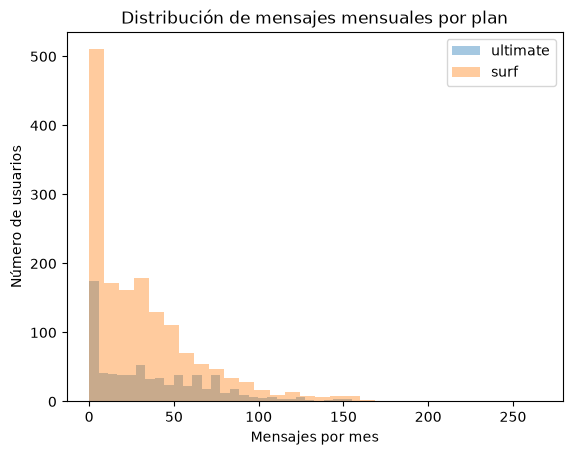

In [117]:

# Distribución de mensajes enviados por mes por plan

for plan in new_data['plan'].unique():
    sub_data = new_data[new_data['plan'] == plan]
    plt.hist(sub_data['messages_per_month'], bins=30, alpha=0.4, label=plan)

plt.title('Distribución de mensajes mensuales por plan')
plt.xlabel('Mensajes por mes')
plt.ylabel('Número de usuarios')

plt.legend()

plt.show()


El histograma confirma que, la mayoría de usuarios, tanto en Surf como en Ultimate, envían muy pocos mensajes al mes. Conforme aumenta el número de mensajes, la cantidad de usuarios disminuye.

En Surf se concentra un mayor número de usuarios en los rangos bajos (pocos mensajes).

En Ultimate, aunque hay menos usuarios en total, la distribución se extiende más hacia valores altos.

Por tanto, una vez más se muestra que surf tiene más usuarios que envían pocos mensajes mientras que ultimate muestra un comportamiento más variado.

Por tanto, el comportamiento en cuanto a mensajes no es similar para los usuarios de los diferentes planes.

### Internet

In [118]:
# Compara la cantidad de tráfico de Internet consumido por usuarios por plan

stat_gb_month_plan = new_data.groupby(['plan','month'])['gb_per_month_rounded'].agg(['mean','var']).reset_index()
print(stat_gb_month_plan)

        plan  month       mean         var
0       surf      1   5.000000   18.000000
1       surf      2  12.222222   41.444444
2       surf      3  13.565217   63.984190
3       surf      4  12.220000   56.215918
4       surf      5  14.116883   58.183527
5       surf      6  15.484536   47.752363
6       surf      7  16.876033   61.476171
7       surf      8  16.882716   71.420942
8       surf      9  16.690722   49.240639
9       surf     10  17.409283   60.725846
10      surf     11  16.431095   54.607824
11      surf     12  18.238994   69.210841
12  ultimate      1   7.250000   14.916667
13  ultimate      2  17.285714   37.904762
14  ultimate      3  18.416667  138.628788
15  ultimate      4  16.333333   85.833333
16  ultimate      5  16.862069   54.194581
17  ultimate      6  15.425532   68.858464
18  ultimate      7  16.491525   64.254237
19  ultimate      8  17.845070   58.047082
20  ultimate      9  17.011628   47.258687
21  ultimate     10  17.716981   54.604852
22  ultimat

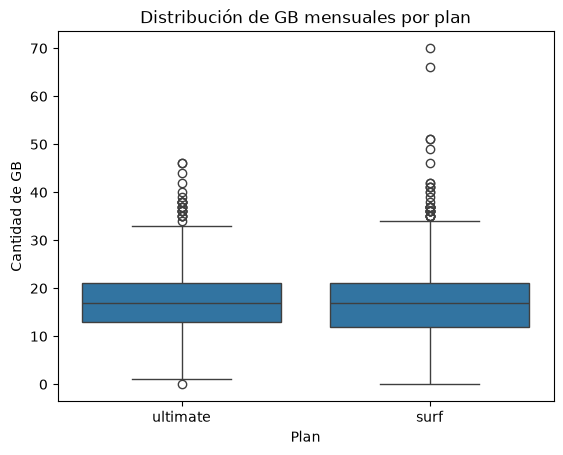

In [119]:

# Traza un diagrama de caja para visualizar la distribución de los gb mensuales por plan

sns.boxplot(data=new_data, 
            x='plan', 
            y='gb_per_month_rounded')

plt.title('Distribución de GB mensuales por plan')
plt.xlabel('Plan')
plt.ylabel('Cantidad de GB')
plt.show()


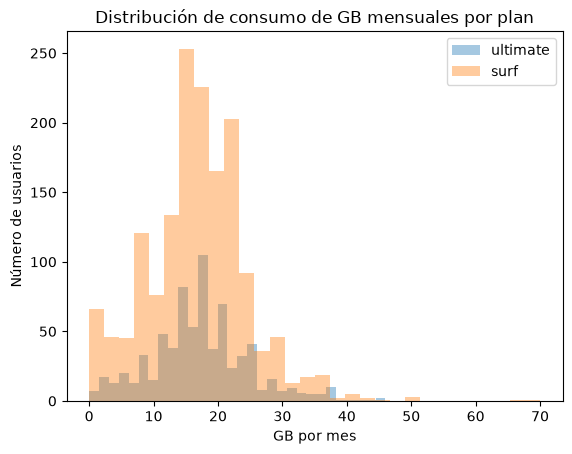

In [120]:
# Distribución de GB usados por mes por plan

for plan in new_data['plan'].unique():
    sub_data = new_data[new_data['plan'] == plan]
    plt.hist(sub_data['gb_per_month_rounded'], bins=30, alpha=0.4, label=plan)

plt.title('Distribución de consumo de GB mensuales por plan')
plt.xlabel('GB por mes')
plt.ylabel('Número de usuarios')

plt.legend()

plt.show()

La media muestra que los usuarios de ultimate usan más el internet que los usuarios de surf, en la mayoría de los meses.

La varianza es mayor para los usuarios de ultimate en algunos meses y en otros sucede lo contrario.

La distribución muestra que la media es cercana para los dos planos, la mayor cantidad de usuarios para ambos planes consume entre 12 y 22 GB por mes aproximadamente.

Para el caso de los usuarios de surf, se encuentran más datos atípicos mayores a 30 mientras que ultimate tiene menos datos atípicos mayores a 30 y pocos datos atípicos menores cercanos a 0. 

En términos generales, se puede concluir que el comportamiento de los usuarios de ambos planes es similar. 

## Ingreso

In [121]:
# Comparar el pago mensual de los usuarios de cada plan

stat_revenue_plan_month = new_data.groupby(['plan','month'])['revenue'].agg(['mean', 'var']).reset_index()
print(stat_revenue_plan_month)

        plan  month       mean          var
0       surf      1  20.000000     0.000000
1       surf      2  34.396667   428.276100
2       surf      3  45.941304  1512.023512
3       surf      4  40.710600  1198.958402
4       surf      5  47.628182  1967.540055
5       surf      6  49.276289  1988.914046
6       surf      7  62.674050  2943.388409
7       surf      8  63.931173  3587.494901
8       surf      9  58.271495  2260.644980
9       surf     10  65.421224  3198.242612
10      surf     11  58.004276  2494.182230
11      surf     12  70.557044  4604.410868
12  ultimate      1  70.000000     0.000000
13  ultimate      2  70.000000     0.000000
14  ultimate      3  74.666667   145.515152
15  ultimate      4  73.000000   120.400000
16  ultimate      5  70.724138    15.206897
17  ultimate      6  71.638298    75.018501
18  ultimate      7  71.898305   104.472238
19  ultimate      8  72.859155   154.808451
20  ultimate      9  72.034884    75.939945
21  ultimate     10  72.311321  

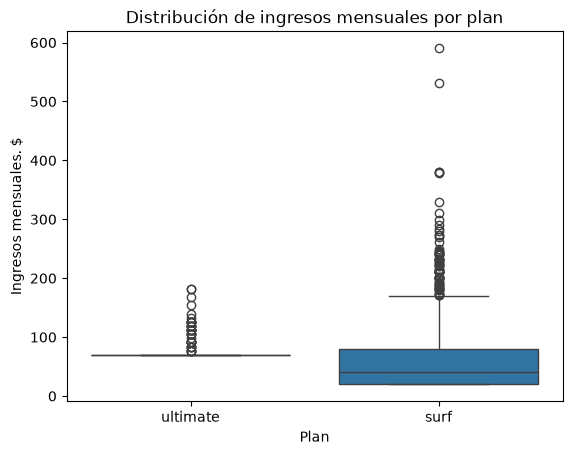

In [122]:
# Traza un diagrama de caja para visualizar la distribución de los ingresos mensuales por plan

sns.boxplot(data=new_data, 
            x='plan', 
            y='revenue')

plt.title('Distribución de ingresos mensuales por plan')
plt.xlabel('Plan')
plt.ylabel('Ingresos mensuales. $')
plt.show()

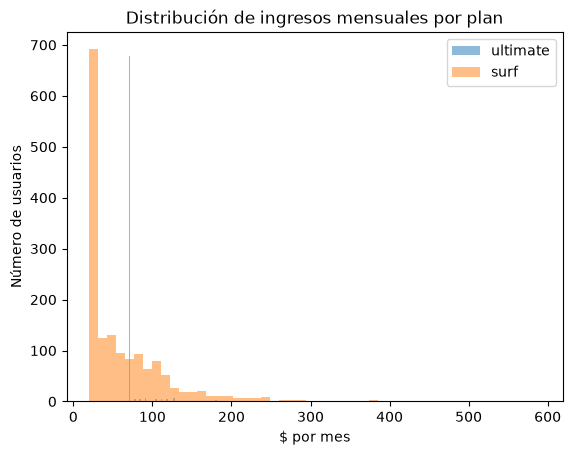

In [123]:
for plan in new_data['plan'].unique():
    sub_data = new_data[new_data['plan'] == plan]
    plt.hist(sub_data['revenue'], bins=50, alpha=0.5, label=plan)

plt.title('Distribución de ingresos mensuales por plan')
plt.xlabel('$ por mes')
plt.ylabel('Número de usuarios')

plt.legend()

plt.show()

In [124]:
# Calcular el total de ingresos anual por plan

rev_yearly_plan = new_data.groupby(['plan'])['revenue'].sum().reset_index()
rev_yearly_plan = rev_yearly_plan.rename(columns={'revenue':'year_rev'})

print(rev_yearly_plan)

       plan  year_rev
0      surf  95491.18
1  ultimate  52066.00



El análisis de ingresos muestra que para los usuarios de surf, la media se va alejando de 20, que es el valor del plan, conforme avanzan los meses. Mientra que las medias de cada mes para los usuarios de ultimate van entre 70 y 74 dólares, lo que muestra datos poco dispersos. La varianza es mayor para los usuarios de surf, lo que indica una mayor dispersión de los valores de ingreso mensual.

En la distribución se confirma lo indicado al ver que para los usuarios de surf hay mayor dispersión hacia arriba, es decir hacia valores mayores a 20 y valores atípicos mayores de 180 aproximadamente y cercanos a 600 dólares. 

Mientras que para los usuarios de surf, la media se mantiene cerca de 70 con muy poca dispersión con valores atípicos hasta 200. 

El ingreso es mayor por usuarios de surf, lo que se deba la dispersió en sus ingresos, como se indica hacia arriba de la media y también a que representan la mayor población. Mientras que en ultimate hay menos usuarios que se mantienen usando mensajos, llamadas, internet dentro de su tarifa. 

Por tanto, la tarifa de prepago que genera más ingresos es la de surf. 


## Prueba las hipótesis estadísticas

Hipótesis nula: Los ingresos promedio de los usuarios de los planes ultimate y surf son iguales.

Hipótesis alternativa: Los ingresos promedio de los usuarios de los planes ultimate y surf son diferentes. 

In [125]:
# Prueba las hipótesis

# Ingresos surf y ultimate por separado

surf_revenue = new_data[new_data['plan'] == 'surf']['revenue']
ultimate_revenue = new_data[new_data['plan'] == 'ultimate']['revenue']

print(surf_revenue)
print(ultimate_revenue)

1        20.00
2        20.00
3        90.09
4        60.00
5        60.00
         ...  
2288    100.00
2289     20.00
2290     70.00
2291     40.00
2292     90.00
Name: revenue, Length: 1573, dtype: float64
0       70.0
19      70.0
20      84.0
26      70.0
27      70.0
        ... 
2258    70.0
2259    70.0
2260    70.0
2261    70.0
2277    70.0
Name: revenue, Length: 720, dtype: float64


In [126]:
# Prueba t de Student

alpha = 0.01

results = st.ttest_ind(surf_revenue, ultimate_revenue, equal_var = False)

# Imprimir valor p

print('Valor p:', results.pvalue)

# Resultado conforme el valor p de la comparación del valor p con el nivel de significancia
if (results.pvalue < alpha):
    print("Rechazamos la hipótesis nula")
else:
    print("No podemos rechazar la hipótesis nula")

Valor p: 3.170390548113581e-15
Rechazamos la hipótesis nula



Para probar la hipótesis se establecen las siguientes condiciones:

- Se establece un nivel de significancia α = 0.01, dado que los valores de ingresos son cercanos y se busca mayor precisión en la comparación.
- Se utiliza la opción equal_var=False, ya que se identificó que las varianzas entre los grupos son diferentes; por lo tanto, se asume que esta diferencia también se refleja en los datos completos.
- Se aplica una prueba de dos colas, porque la hipótesis planteada busca determinar si los ingresos de un plan difieren de los del otro, sin especificar si son mayores o menores.

Con respecto a los resultados se tiene que:

El valor p obtenido es 3.17e-15, que es un valor significativamente menor que 0.01.

En consecuencia, se rechaza la hipótesis nula, lo que indica que los ingresos promedio de los usuarios del plan Surf son estadísticamente distintos de los del plan Ultimate.



Hipótesis nula: El ingreso promedio de los usuarios en el área de estados Nueva York-Nueva Jersey es igual al de los usuarios de otras regiones.

Hipótesis alternativa: El ingreso promedio de los usuarios en el área de estados Nueva York-Nueva Jersey es diferente al de los usuarios de otras regiones.


In [127]:
# Prueba las hipótesis

# Combinar la información de usuarios según el área y el ingreso.

users_area = users[['user_id','city']]
new_data_area = new_data.merge(users_area, on='user_id')
new_data_area = new_data_area[['user_id', 'city', 'revenue']]

print(new_data_area.head())

   user_id                                   city  revenue
0     1000  Atlanta-Sandy Springs-Roswell, GA MSA    70.00
1     1001        Seattle-Tacoma-Bellevue, WA MSA    20.00
2     1001        Seattle-Tacoma-Bellevue, WA MSA    20.00
3     1001        Seattle-Tacoma-Bellevue, WA MSA    90.09
4     1001        Seattle-Tacoma-Bellevue, WA MSA    60.00


In [128]:
# Separar ingresos por región

ny_nj_revenue = new_data_area[new_data_area['city'].isin(['New York-Newark-Jersey City, NY-NJ-PA MSA'])]['revenue']
other_revenue = new_data_area[~new_data_area['city'].isin(['New York-Newark-Jersey City, NY-NJ-PA MSA'])]['revenue']

print(ny_nj_revenue.head())
print(other_revenue.head())

56     20.00
57     38.84
75     20.00
76    100.00
77     20.00
Name: revenue, dtype: float64
0    70.00
1    20.00
2    20.00
3    90.09
4    60.00
Name: revenue, dtype: float64


In [129]:
# Prueba t de Student 

alpha = 0.01
results = st.ttest_ind(ny_nj_revenue, other_revenue, equal_var=False)

print("Valor p:", results.pvalue)

if (results.pvalue < alpha):
    print("Rechazamos la hipótesis nula: los ingresos promedio son diferentes.")
else:
    print("No podemos rechazar la hipótesis nula: no hay evidencia de diferencia.")

Valor p: 0.03352561588530015
No podemos rechazar la hipótesis nula: no hay evidencia de diferencia.



Para probar la hipótesis se establecen las siguientes condiciones:

- Se establece un nivel de significancia α = 0.01, para tener una mayor precisión al comparar los datos dado que al ser conocidos se identifican como cercanos para las diferentes ciudades.
- Se utiliza la opción equal_var=False, ya que al conocer que en análisis previos se tienen varianzas distintas para promedios mensuales, se puede entonces tener varianzas distintas entre los valores de ciudades. 
- Se aplica una prueba de dos colas porque la hipótesis planteada busca determinar si los ingresos de una ciudad difieren de los de otras ciudades, sin especificar si son mayores o menores.

Con respecto a los resultados se tiene que:

El valor p obtenido es 0.033, que es un valor mayor que 0.01.

En consecuencia, no se puede rechazar la hipótesis nula. Es decir, que estadísticamente no hay evidencia de diferencia entre el ingreso promedio de los usuarios en el área de estados Nueva York-Nueva Jersey con el de los usuarios de otras regiones, sus ingresos pueden ser iguales. 


## Conclusión general

El objetivo del proyecto fue identificar cuál de las tarifas de prepago de Megaline, Surf o Ultimate, genera mayores ingresos, con el fin de orientar decisiones de marketing y presupuesto. Para ello se analizaron los datos de 500 clientes durante 2018, considerando llamadas, mensajes y uso de internet. La estrategia consistió en calcular los ingresos mensuales por usuario, comparar los resultados entre planes y aplicar pruebas estadísticas para determinar si las diferencias observadas eran significativas.

En la fase inicial se realizó una limpieza y preparación de los datos. Se revisaron las tablas disponibles, se exploraron con métodos como head() e info(), se revisó tipos de datos y se buscó, aunque no se identificó datos duplicados ni valores ausentes. Posteriormente, se integraron los distintos DataFrames de llamadas, mensajes e internet en un único conjunto, asegurando que cada fila representara el consumo mensual de un usuario. Los valores faltantes en esta última tabla se reemplazaron por cero y se ajustaron las columnas para reflejar correctamente cantidades discretas.

El análisis descriptivo mostró que los usuarios de ambos planes tienen comportamientos similares en la duración de las llamadas y en el uso de internet, aunque Surf presenta mayor dispersión y más casos extremos. En cuanto a los mensajes, se evidenció que los usuarios de Ultimate envían más mensajes en promedio y con mayor variabilidad, mientras que Surf concentra más usuarios en rangos bajos. Estas diferencias en patrones de consumo fueron confirmadas con histogramas y diagramas de caja, que reflejaron la concentración de usuarios y la presencia de valores atípicos.

Al calcular los ingresos mensuales, se observó que los usuarios de Surf generan ingresos más dispersos, con valores que superan ampliamente la tarifa base de 20 dólares debido a cargos por excedentes. En contraste, Ultimate mantiene ingresos más estables alrededor de 70 dólares, con poca variación. La mayor cantidad de usuarios en Surf y la dispersión hacia valores altos explican por qué este plan resulta más rentable en términos de ingresos totales, aunque Ultimate ofrece mayor estabilidad en el comportamiento de sus clientes.

Finalmente, las pruebas de hipótesis confirmaron que los ingresos promedio de Surf y Ultimate son estadísticamente diferentes, con un p‑valor muy inferior al nivel de significancia α = 0.01. En cambio, al comparar los ingresos promedio de los usuarios del área NY‑NJ con los de otras regiones, no se encontraron diferencias significativas. 

En conclusión, el plan Surf genera mayores ingresos para Megaline, principalmente por su mayor número de usuarios y la dispersión en el consumo, mientras que Ultimate mantiene un perfil más homogéneo y estable.